# SANS triage prototype (v0.1)
Synthetic astronauts → in-flight eye exams → rule-based triage (NASA SANS thresholds) → checks.
Synthetic data only. Tier actions are drafts for clinician review. Sources for every number: `sans_cdss/parameters.py`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # make the sans_cdss package importable

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sans_cdss import parameters as prm
from sans_cdss.generator import make_astronauts, make_sessions, remeasure
from sans_cdss.triage import triage_sessions, explain, TIER_NAMES, DRAFT_ACTIONS
from sans_cdss import evaluate as ev
from sans_cdss.vignettes import build_packet

OUT = pathlib.Path("../outputs"); FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)

# chart styling: recessive axes, one ordinal blue ramp for tiers (validated for CVD + contrast)
TIER_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "figure.dpi": 110})

## 1. Parameters
Count by kind. Assumptions = what needs clinician review.

In [2]:
prov = prm.provenance_table()
prov.to_csv(OUT / "parameter_provenance.csv", index=False)
display(prov.groupby(["group", "kind"]).size().unstack(fill_value=0))
display(prov[prov.kind == "assumption"][["parameter", "value", "note"]])

kind,assumption,derived,reported
group,,,
simulator,22,10,16
triage,1,1,5


,parameter,value,note
8,rho_cup_ode,-0.45,"direction from paper, strength mine"
9,p_mtrr66_risk_allele,0.5,approx; verify in gnomAD
10,p_shmt1_1420_risk_allele,0.65,approx; verify in gnomAD
11,rho_genetic_ode,0.2,"flight effect size unknown, kept small"
14,dtrt_shift,-10.0,allows ~0 change
15,dtrt_tau_days,25.0,rise time constant
16,dtrt_tau_logsd,0.3,person-to-person spread
23,p_frisen_given_dtrt55,0.6,tuned to ~17% overall
24,p_frisen_given_dtrt20,0.15,
25,p_frisen_given_low,0.02,


## 2. Cohort
Astronaut table = hidden truth. Exam table = truth + measurement noise (FD10…FD150, R−30).

In [3]:
N = 2000
astronauts = make_astronauts(N, seed=0)
sessions = make_sessions(astronauts, schedule="dense", seed=1)
print(f"{len(astronauts)} synthetic astronauts, {len(sessions)} exams")
display(sessions.head(8))

2000 synthetic astronauts, 12504 exams


,astronaut_id,flight_day,dtrt_true,dtrt_obs,frisen_ge1,folds_present,macular_folds,distorted_central_vision,globe_flattening,gf_moderate,refr_shift_D,visual_field_loss,reports_blurred_vision,iop_mmhg,choroid_um
0,SYN-0000,10,3.8,6.2,False,False,False,False,False,False,0.10,False,True,15.5,333.2
1,SYN-0000,30,8.0,14.3,False,False,False,False,False,False,0.06,False,True,14.7,360.4
2,SYN-0000,60,10.3,12.9,False,False,False,False,False,False,0.04,False,True,15.2,368.3
3,SYN-0000,90,11.0,5.9,False,False,False,False,False,False,-0.02,False,True,14.7,371.7
4,SYN-0000,120,11.2,11.5,False,False,False,False,False,False,-0.03,False,True,14.4,366.0
5,SYN-0000,137,11.3,11.3,False,False,False,False,False,False,-0.03,False,True,16.5,376.4
6,SYN-0001,10,5.0,-13.9,False,False,False,False,False,False,-0.22,False,True,18.0,147.2
7,SYN-0001,30,12.0,13.5,False,False,False,False,False,False,0.07,False,True,20.3,153.9


## 3. Realism checks
Prevalence was tuned (calibration check). Carter 2026 time course was not (independent check).

In [4]:
prev, traj, cup = ev.validate_generator(astronauts, sessions)
display(prev.style.format({"synthetic": "{:.0%}", "published": "{:.0%}"}).hide(axis="index"))
display(traj.style.format({"synthetic": "{:.2f}"}).hide(axis="index"))
display(cup.style.format({"synthetic": "{:.0%}"}).hide(axis="index"))

finding,synthetic,published,source
dTRT >= 20 um (earliest-indication ODE),63%,64%,Brunstetter 2023
dTRT >= 55 um (clinically concerning ODE),17%,18%,Macias 2020 intro: 16-19%
Chorioretinal folds,16%,15%,Brunstetter 2023; Ferguson 2023: 17%
Globe flattening,25%,26%,Brunstetter 2023
Hyperopic shift >= +0.75 D,15%,14%,Brunstetter 2023
Frisen grade >= 1,17%,17%,Valencia 2023: 17% of images


check,synthetic,published,source
"Mean dTRT, FD10 (um)",11.38,11.9 (95% CI 6.6-17.3),Macias 2020
"Mean dTRT, FD150 (um)",34.40,"27.6 (Macias, n=11); 38.2 (Pardon, n=31)",Macias 2020; Pardon 2022
Correlation dTRT FD30 vs FD150,0.90,0.89 (0.80-0.94),Carter 2026
P(FD150 >= 55 | FD30 < 20),0.00,2% (1-15%),Carter 2026
P(FD150 >= 55 | FD30 20-55),0.24,34% (19-60%),Carter 2026
P(FD150 >= 55 | FD30 29-55),0.39,58% (37-90%),Carter 2026


check,synthetic,published (Pardon 2022)
P(peak dTRT > 19.4 | cup >= 0.3 mm3),38%,0% (none of ~31 crew)
P(peak dTRT > 19.4 | cup < 0.3 mm3),71%,most


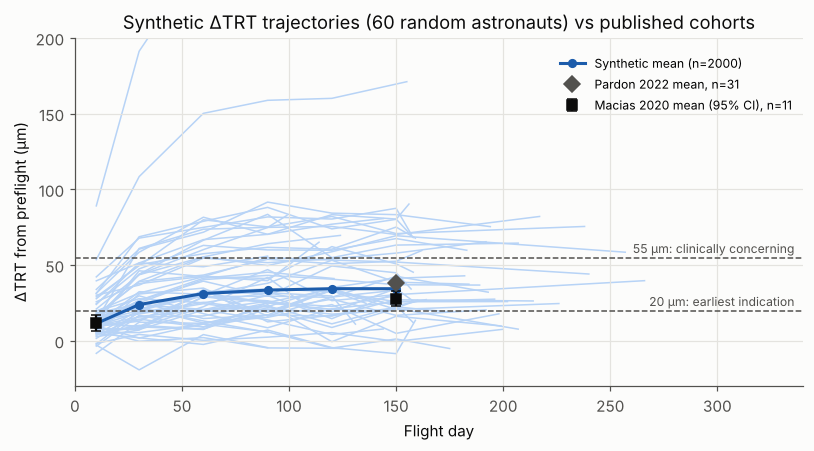

In [5]:
# Figure 1: synthetic dTRT trajectories vs published means
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sample = sessions[sessions.astronaut_id.isin(astronauts.astronaut_id.sample(60, random_state=3))]
for _, g in sample.groupby("astronaut_id"):
    ax.plot(g.flight_day, g.dtrt_obs, color="#b7d3f6", lw=1, zorder=1)
dense = sessions[sessions.flight_day.isin([10, 30, 60, 90, 120, 150])]
m = dense.groupby("flight_day").dtrt_obs.mean()
ax.plot(m.index, m.values, color="#1c5cab", lw=2, marker="o", ms=5, zorder=3, label="Synthetic mean (n=2000)")
ax.errorbar([10, 150], [11.9, 27.6], yerr=[[11.9-6.6, 27.6-22.7], [17.3-11.9, 32.6-27.6]], fmt="s", ms=7,
            color=INK, capsize=3, zorder=4, label="Macias 2020 mean (95% CI), n=11")
ax.plot([150], [38.2], marker="D", ms=7, color=MUTED, ls="none", zorder=4, label="Pardon 2022 mean, n=31")
for y, lab in [(20, "20 µm: earliest indication"), (55, "55 µm: clinically concerning")]:
    ax.axhline(y, color=MUTED, ls="--", lw=1); ax.text(336, y + 3, lab, color=MUTED, fontsize=8, ha="right")
ax.set(xlabel="Flight day", ylabel="ΔTRT from preflight (µm)", ylim=(-30, 200), xlim=(0, 340),
       title="Synthetic ΔTRT trajectories (60 random astronauts) vs published cohorts")
ax.title.set_color(INK); ax.legend(frameon=False, fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.98))
fig.tight_layout(); fig.savefig(FIG / "fig1_dtrt_trajectories.png"); plt.show()

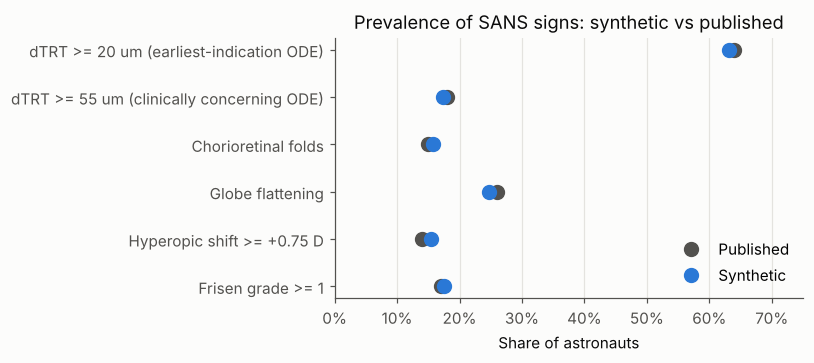

In [6]:
# Figure 2: prevalence, synthetic vs published (paired dots)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
y = np.arange(len(prev))[::-1]
ax.hlines(y, prev.published, prev.synthetic, color=GRID, lw=3)
ax.plot(prev.published, y, "o", ms=9, color=MUTED, label="Published")
ax.plot(prev.synthetic, y, "o", ms=9, color="#2a78d6", label="Synthetic")
ax.set_yticks(y, prev.finding); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set(xlim=(0, 0.75), xlabel="Share of astronauts", title="Prevalence of SANS signs: synthetic vs published")
ax.title.set_color(INK); ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "fig2_prevalence_check.png"); plt.show()

## 4. Triage
| Tier | Triggers (any one) |
|---|---|
| 0 | none |
| 1 | ΔTRT ≥ 20 µm · folds · globe flattening · shift ≥ +0.75 D |
| 2 | ΔTRT ≥ 55 µm or Frisén ≥ 1 · folds near macula · moderate GF |
| 3 | visual field loss · distorted central vision · shift ≥ +1.75 D (assumed) |

Highest tier with a reason wins. FD30 flag (Carter 2026) is a warning only.

In [7]:
triaged = triage_sessions(sessions)
# three example exams, one per non-zero tier, with their explanations
for t in (1, 2, 3):
    row = triaged[triaged.tier == t].iloc[0]
    print(f"--- {row.astronaut_id}, flight day {row.flight_day}")
    print(explain(row)); print()

--- SYN-0003, flight day 30
Tier 1: Earliest indication
  because: dTRT 25 um >= 20 um
  draft action: Increase surveillance: add interim OCT; review trend at next exam; notify flight surgeon at routine conference.

--- SYN-0002, flight day 30
Tier 2: Clinically concerning
  because: Frisen grade >= 1 on fundus imaging
  draft action: Flight surgeon + ground ophthalmology review (timing TBD by clinicians); consider countermeasures per flight surgeon; flag for post-flight lumbar puncture (NASA: within 7-14 days of return).

--- SYN-0038, flight day 30
Tier 3: Acute functional impact
  because: Visual field loss (e.g., enlarged blind spot)
  draft action: Urgent escalation to flight surgeon; functional vision testing; mission-impact assessment.



## 5. Results

In [8]:
display(ev.tier_summary(triaged).style.format({"share": "{:.1%}"}))
display(ev.criterion_drivers(triaged).style.format({"share_of_tier": "{:.0%}"}).hide(axis="index"))

,n,share
0 - No SANS signs,359,17.9%
1 - Earliest indication,863,43.1%
2 - Clinically concerning,726,36.3%
3 - Acute functional impact,52,2.6%


tier,reason,share_of_tier
1,dTRT # um >= # um,93%
1,Globe flattening present,7%
1,Hyperopic shift # D >= # D,4%
1,Chorioretinal folds present,2%
2,dTRT # um >= # um,45%
2,Frisen grade >= 1 on fundus imaging,42%
2,Moderate globe flattening,16%
2,Chorioretinal folds near the macula,12%
3,Distorted central vision,44%
3,"Visual field loss (e.g., enlarged blind spot)",35%


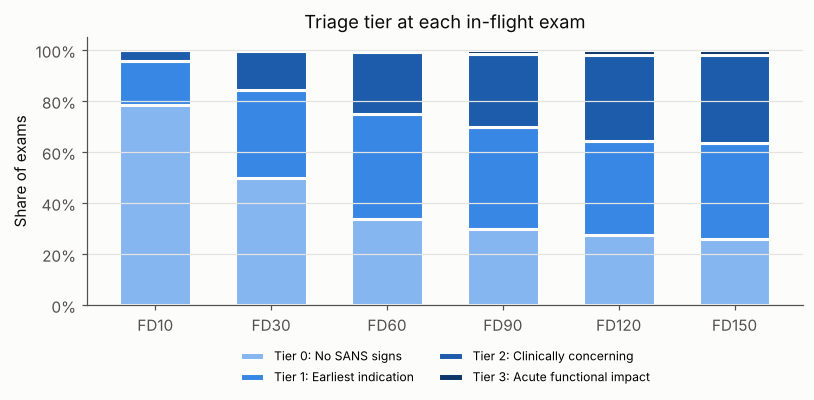

In [9]:
# Figure 3: tier mix by flight day (stacked, ordinal blues, 2px surface gaps)
tbd = ev.tier_by_day(triaged)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bottom = np.zeros(len(tbd)); x = np.arange(len(tbd))
for i, col in enumerate(tbd.columns):
    ax.bar(x, tbd[col], bottom=bottom, color=TIER_COLORS[i], width=0.62, edgecolor="#fcfcfb", linewidth=2,
           label=f"Tier {i}: {col}")
    bottom += tbd[col].values
ax.set_xticks(x, [f"FD{d}" for d in tbd.index]); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set(ylabel="Share of exams", title="Triage tier at each in-flight exam"); ax.title.set_color(INK)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout(); fig.savefig(FIG / "fig3_tiers_by_day.png"); plt.show()

## 6. Robustness
Test-retest: same eyes, fresh noise → how often the tier changes.

In [10]:
rt = ev.test_retest(triaged, astronauts, remeasure)
print(f"Exam-level tier agreement on re-measurement: {rt['exam_level_agreement']:.1%}")
print(f"Quadratic-weighted kappa: {rt['exam_level_kappa']:.2f}")
display(rt["crosstab"])

Exam-level tier agreement on re-measurement: 85.2%
Quadratic-weighted kappa: 0.89


measurement B,0,1,2,3
measurement A,,,,
0,4326,743,0,0
1,779,3376,155,2
2,0,162,2810,4
3,0,2,4,141


Threshold what-ifs: % of astronauts whose final tier changes vs 20/55 µm.

In [11]:
sens = ev.threshold_sensitivity(sessions, earliest=(15, 20, 25), concerning=(45, 55, 65))
display(sens.style.format({"pct_reclassified": "{:.1f}%", "pct_tier2plus": "{:.1f}%"}).hide(axis="index"))

earliest_um,concerning_um,pct_reclassified,pct_tier2plus
15,45,15.5%,46.0%
15,55,8.4%,38.9%
15,65,11.8%,35.4%
20,45,7.1%,46.0%
20,55,0.0%,38.9%
20,65,3.5%,35.4%
25,45,14.6%,46.0%
25,55,7.5%,38.9%
25,65,10.9%,35.4%


## 7. Clinician vignettes
10 per tier, shuffled, engine answer kept in a separate file.

In [12]:
packet, key = build_packet(triaged, astronauts, per_tier=10)
packet.to_csv(OUT / "vignette_packet_for_clinicians.csv", index=False)
key.to_csv(OUT / "vignette_answer_key_DO_NOT_SHARE.csv", index=False)
print(packet.vignette.iloc[0]); print()
print(packet.vignette.iloc[1])

45-year-old male astronaut (no prior spaceflight), flight day 159 of 189. Change in peripapillary total retinal thickness (dTRT) from preflight: +28 um. Refraction change from preflight: +0.05 D (spherical equivalent). Fundus: no Frisen-gradable disc edema. OCT: no chorioretinal folds. Ultrasound: no globe flattening. Symptoms/function: no complaints; visual field not tested. IOP 13 mmHg.

49-year-old male astronaut (no prior spaceflight), flight day 140 of 170. Change in peripapillary total retinal thickness (dTRT) from preflight: +45 um. Refraction change from preflight: +0.80 D (spherical equivalent). Fundus: Frisen grade >= 1 disc edema. OCT: chorioretinal folds extending toward the macula. Ultrasound: mild posterior globe flattening. Symptoms/function: reports blurred near vision; reports distorted central vision. IOP 17 mmHg.


Kappa demo with a **simulated** rater (25% of tiers moved ±1). Swap in real ratings.

In [13]:
rng = np.random.default_rng(0)
fake = key.engine_tier.to_numpy().copy()
move = rng.random(len(fake)) < 0.25
fake[move] = np.clip(fake[move] + rng.choice([-1, 1], move.sum()), 0, 3)
print("Unweighted kappa (simulated rater):", round(ev.cohen_kappa(key.engine_tier, fake), 2))
print("Quadratic-weighted kappa (simulated rater):", round(ev.cohen_kappa(key.engine_tier, fake, "quadratic"), 2))

Unweighted kappa (simulated rater): 0.8
Quadratic-weighted kappa (simulated rater): 0.94


In [14]:
# save the full synthetic dataset
astronauts.drop(columns=[c for c in astronauts if c.startswith("u_")]).to_csv(OUT / "synthetic_astronauts.csv", index=False)
triaged.to_csv(OUT / "synthetic_exams_triaged.csv", index=False)
print("Saved to", OUT.resolve())

Saved to /home/claude/sans-triage-prototype/outputs


## 8. Limitations
* Calibrated to summary stats from small cohorts (n = 11–43).
* One worst eye; no laterality, MRI, pre/post-flight.
* 23/55 parameters are assumptions.
* Cup-volume effect weaker than Pardon 2022; late progression a bit low vs Carter 2026.
* Frisén grader disagreement not simulated, so test-retest understates noise.

Next: clinician review, vignette grading → kappa, rate-of-change rules, orbital ultrasound action.